# Chapitre 6 - Cours 4 : index secondaires et partitionnement

Tant qu'on accède aux données par leur clé, le partitionnement est simple : la clé de
partitionnement désigne la partition, donc le nœud. Mais une vraie application veut aussi
chercher **par valeur** : toutes les voitures rouges, toutes les commandes d'un client,
tous les documents qui contiennent un mot. C'est le rôle des **index secondaires**, et
ils ne se laissent pas découper selon la clé principale. Ce notebook couvre la section
*Partitioning and Secondary Indexes* (sous-sections *Partitioning Secondary Indexes by Document* et *Partitioning Secondary Indexes by Term*).

**Plan.**

1. Le problème : un index secondaire ne suit pas le découpage des données.
2. Les index locaux (partitionnés par document) : écrire sur une partition, lire partout.
3. Le prix du scatter/gather : latence de queue et débit qui ne passe pas à l'échelle.
4. Les index globaux (partitionnés par terme) : lire une partition, écrire sur plusieurs.
5. Comparer et choisir : un modèle de coût et son point de bascule.

In [1]:
import math
from collections import Counter

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from ddia import partitioning as P
from ddia.diagrams import Diagram
from ddia.timelines import SpaceTime
from ddia.plotting import (AMBER, COLORS, GRAY, GREEN, INDIGO, LIGHT, ROSE, SKY, SLATE, TEAL, VIOLET,
                           annotate_bars, finish, set_style, subtitle)

set_style()
plt.rcParams["axes.titlepad"] = 16
pd.set_option("display.precision", 2)
rng = np.random.default_rng(0)
fmt = lambda v: f"{v:,.0f}".replace(",", " ")
SH = "partition"          # vocabulaire de l'édition, pour les figures
SHS = "partitions"
FEM = "e"                              # accord en genre du mot de l'édition

## 1. Le problème : un index secondaire ne suit pas le découpage (section *Partitioning and Secondary Indexes*)

**Le scénario.** Un site d'annonces de voitures d'occasion. Chaque annonce a un
identifiant unique, qui sert de clé de partitionnement : la partition d'une annonce est
déterminée par le haché de son identifiant. Les visiteurs, eux, ne connaissent pas les
identifiants : ils filtrent par **couleur** et par **marque**. Il faut donc des index
secondaires sur ces deux champs : pour chaque valeur (un **terme**, comme
`color:rouge`), la liste des identifiants d'annonces qui la portent. On retrouve la
**liste de postings** de l'index inversé du chapitre 3.

Une entrée d'index secondaire n'identifie pas un enregistrement : elle en désigne
potentiellement des milliers, et rien ne dit qu'ils sont au même endroit. Générons
20 000 annonces (fonction `P.car_listings`, popularités inégales des couleurs et des
marques) réparties sur 8 partitions par haché de l'identifiant, et regardons où se trouvent
les voitures rouges.

In [2]:
N_SHARDS = 8
cars = P.car_listings(20_000, seed=1)
shard_of = np.array([P.doc_shard(c["id"], N_SHARDS) for c in cars])
colors = np.array([c["color"] for c in cars])

par_couleur = pd.crosstab(colors, shard_of).loc[P.COLORS_CARS]
par_couleur.index.name = "couleur"
par_couleur.columns = [f"{SH} {s}" for s in par_couleur.columns]
par_couleur.iloc[:4]

,partition 0,partition 1,partition 2,partition 3,partition 4,partition 5,partition 6,partition 7
couleur,,,,,,,,
rouge,740,801,793,742,773,793,817,802
noir,434,450,436,438,471,428,450,432
blanc,277,296,328,333,341,324,323,320
gris,228,250,267,264,243,252,232,263


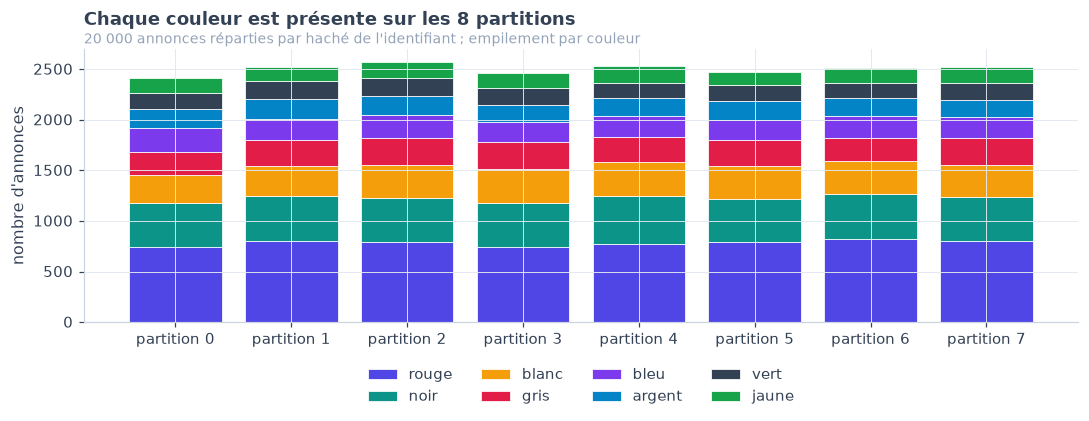

In [3]:
fig, ax = plt.subplots(figsize=(10, 4))
bottom = np.zeros(N_SHARDS)
for i, col in enumerate(P.COLORS_CARS):
    vals = par_couleur.loc[col].values
    ax.bar(np.arange(N_SHARDS), vals, bottom=bottom, color=COLORS[i % len(COLORS)], label=col,
           edgecolor="white", lw=0.5)
    bottom += vals
ax.set_xticks(np.arange(N_SHARDS), [f"{SH} {s}" for s in range(N_SHARDS)])
ax.set_ylabel("nombre d'annonces")
ax.set_title(f"Chaque couleur est présente sur les {N_SHARDS} {SHS}")
subtitle(ax, "20 000 annonces réparties par haché de l'identifiant ; empilement par couleur")
ax.legend(ncol=4, loc="upper center", bbox_to_anchor=(0.5, -0.12))
plt.tight_layout(); plt.show()

Chaque partition contient environ un huitième de chaque couleur : la répartition par
identifiant est **orthogonale** aux valeurs recherchées. Pour une couleur présente
sur $m$ annonces placées au hasard, la probabilité qu'une partition donnée n'en contienne
aucune vaut $(1 - 1/n)^m$ : avec $m = 1\,205$ voitures jaunes et $n = 8$, c'est
$10^{-70}$. Toute requête « toutes les voitures jaunes » concerne donc **tous** les
partitions. Il n'existe que deux façons de s'en sortir : soit chaque partition indexe ses
propres documents (index **local**), soit l'on construit un index qui couvre toutes les
données et que l'on découpe à son tour, selon le terme (index **global**).

> **À retenir.** Une clé de partitionnement sert les accès par clé ; une valeur
> d'index secondaire désigne des enregistrements dispersés sur toutes les partitions.
> Il faut choisir qui paie : la lecture (index local) ou l'écriture (index global).

## 2. Les index locaux, partitionnés par document (section *Partitioning Secondary Indexes by Document*)

**Le principe.** Chaque partition tient ses propres index secondaires, qui ne couvrent que
ses documents ; elle ignore tout du contenu des autres. On parle d'index **local**, ou
d'index **partitionné par document** (« document-partitioned ») : l'index est découpé
exactement comme les données.

- **Écriture** : ajouter, modifier ou supprimer une annonce ne touche que la partition
  qui la contient, données et index ensemble. L'index peut être mis à jour dans la même
  transaction locale que le document : il reste cohérent sans effort.
- **Lecture** : pour « toutes les voitures rouges », il faut envoyer la requête à
  **tous** les partitions et fusionner les réponses : c'est le **scatter/gather**.

Le schéma ci-dessous est construit à partir des 20 premières annonces, réparties sur 3
partitions : chaque index local ne liste que les identifiants de sa partition.

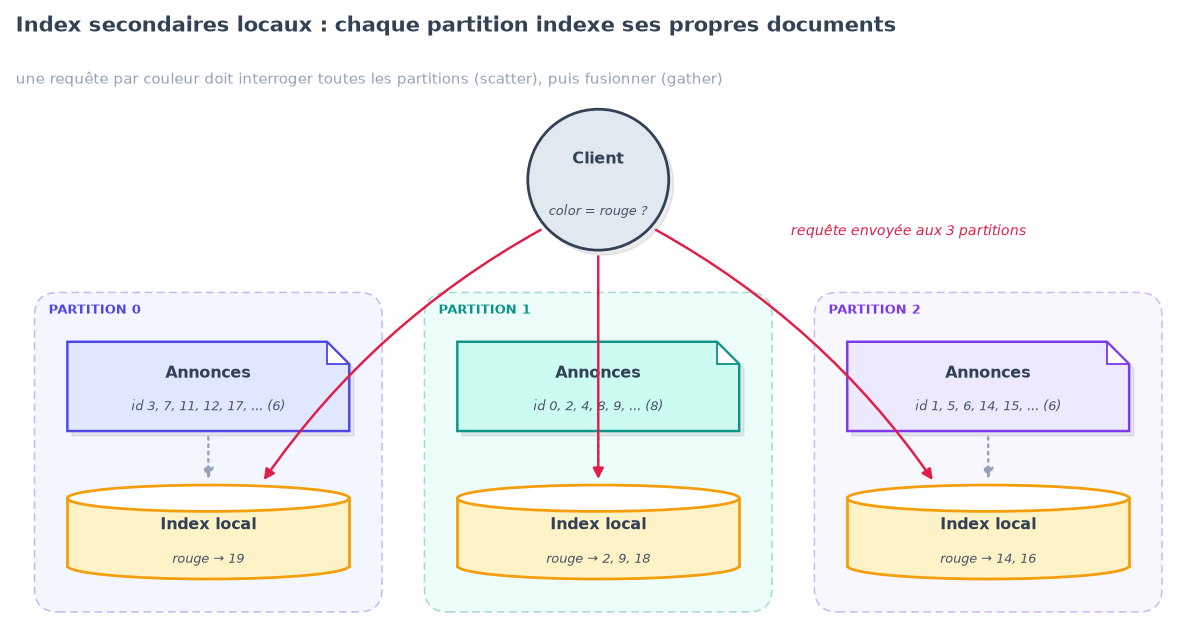

voitures rouges (ensemble des 20) : [2, 9, 14, 16, 18, 19]


In [4]:
small = cars[:20]
loc3 = P.LocalIndexDB(3)
for c in small:
    loc3.put(c)


def postings(idx, term, k=4):
    ids = sorted(idx.get(term, set()))
    txt = ", ".join(map(str, ids[:k])) + (" ..." if len(ids) > k else "")
    return txt or "(vide)"


def id_list(ids, k=5):
    ids = sorted(ids)
    return "id " + ", ".join(map(str, ids[:k])) + (f", ... ({len(ids)})" if len(ids) > k else "")


d = Diagram(12.5, 5.6, title="Index secondaires locaux : chaque " + SH + " indexe ses propres documents",
            subtitle="une requête par couleur doit interroger toutes les partitions (scatter), puis fusionner (gather)")
d.box("client", 6.25, 4.75, "Client", sub="color = rouge ?", kind="user", w=1.5, color=SLATE)
xs = [2.1, 6.25, 10.4]
for s, x in enumerate(xs):
    d.group(x - 1.85, 0.15, x + 1.85, 3.55, f"{SH} {s}", color=[INDIGO, TEAL, VIOLET][s])
    d.box(f"docs{s}", x, 2.55, "Annonces", sub=id_list(loc3.docs[s]), kind="doc", w=3.0, h=0.95,
          color=[INDIGO, TEAL, VIOLET][s])
    d.box(f"idx{s}", x, 1.0, "Index local", sub="rouge → " + postings(loc3.index[s], "color:rouge"),
          kind="db", w=3.0, h=1.0, color=AMBER)
    d.arrow(f"docs{s}", f"idx{s}", style="dotted", color=GRAY)
for s in range(3):
    d.arrow("client", f"idx{s}", None, color=ROSE, rad=0.0 if s == 1 else (0.12 if s == 0 else -0.12))
d.note(8.3, 4.2, "requête envoyée aux 3 " + SHS, color=ROSE, ha="left")
d.show()
print("voitures rouges (ensemble des 20) :", sorted(c["id"] for c in small if c["color"] == "rouge"))

Vérifions sur les 20 000 annonces : l'index local donne exactement le même résultat
qu'un parcours complet, et le compte des partitions sollicitées résume le compromis.

In [5]:
loc = P.LocalIndexDB(N_SHARDS)
touched_w = [loc.put(c) for c in cars]
ids, n_q = loc.query("color", "rouge")
ref = {c["id"] for c in cars if c["color"] == "rouge"}
pd.DataFrame({
    "opération": ["écrire une annonce", "lire une annonce par id", "chercher color = rouge"],
    f"{SHS} sollicité{FEM}s": [max(touched_w), 1, n_q],
    "remarque": ["données et index sur le même nœud", "la clé désigne " + "la partition",
                 f"{len(ids)} résultats, identiques au parcours complet : {ids == ref}"],
})

,opération,partitions sollicitées,remarque
0,écrire une annonce,1,données et index sur le même nœud
1,lire une annonce par id,1,la clé désigne la partition
2,chercher color = rouge,8,"6261 résultats, identiques au parcours complet..."


Deux nuances importantes :

- si la requête porte **aussi** sur la clé de partitionnement (« les voitures rouges de
  l'annonce 42 », ou plus réalistement « les commandes du client 7 » quand le client est
  la clé), on interroge une seule partition ;
- si l'on ne veut que **quelques** résultats (une première page de 10 voitures rouges),
  n'importe quelle partition peut suffire : chacune en contient des centaines.

C'est l'approche de MongoDB, Riak, Cassandra, Elasticsearch, SolrCloud et VoltDB ; dans
un moteur de recherche plein texte, chaque partition contient un sous-ensemble des
documents et leur index inversé complet.

**L'index « maison ».** Si la base ne propose qu'un modèle clé-valeur, la tentation est
grande de maintenir soi-même une table `couleur -> ids` dans le code applicatif. Le
danger : l'écriture du document et celle de l'index sont deux opérations séparées.
Simulons 10 000 mises à jour (changement de couleur) avec 0,5 % d'échecs entre les deux
écritures (processus tué, délai dépassé) : l'index dérive silencieusement.

In [6]:
docs = {c["id"]: c["color"] for c in cars[:2_000]}
index = {}
for i, col in docs.items():
    index.setdefault(col, set()).add(i)
rng_m = np.random.default_rng(3)
crashes = 0
for _ in range(10_000):
    i = int(rng_m.integers(0, 2_000))
    new = str(rng_m.choice(P.COLORS_CARS))
    old = docs[i]
    docs[i] = new                         # 1) on écrit le document
    if rng_m.random() < 0.005:            # le processus meurt entre les deux écritures
        crashes += 1
        continue
    index[old].discard(i)                 # 2) on met à jour l'index
    index.setdefault(new, set()).add(i)

faux = sum(1 for col, s in index.items() for i in s if docs[i] != col)
manquants = sum(1 for i, col in docs.items() if i not in index.get(col, set()))
print(f"{crashes} échecs entre les deux écritures -> {faux} entrées d'index fausses, {manquants} documents introuvables par leur couleur")

57 échecs entre les deux écritures -> 35 entrées d'index fausses, 10 documents introuvables par leur couleur


Chaque échec laisse une entrée fausse (le document apparaît encore sous son ancienne
couleur) et un document introuvable sous la nouvelle. Une mise à jour ultérieure du même
document le réindexe sous sa couleur suivante, ce qui efface la plupart des documents
introuvables, mais l'entrée fausse, elle, reste en place : les erreurs s'accumulent
(ici 35 entrées fausses et 10 documents introuvables après 57 échecs). Rien ne signale
le problème : il faut une transaction
multi-objets (chapitre 7) ou laisser la base maintenir l'index.

> **À retenir.** Un index local est découpé comme les données : une écriture ne touche
> qu'une partition et l'index reste trivialement cohérent. En échange, une recherche par
> valeur sans clé de partitionnement doit interroger toutes les partitions.

## 3. Le prix du scatter/gather (section *Partitioning Secondary Indexes by Document*)

Interroger les partitions **en parallèle** évite d'additionner leurs temps de réponse, mais
la requête complète attend le **plus lent**. C'est l'amplification de la latence de
queue du chapitre 1 : si chaque partition répond lentement avec une
probabilité $p$ (pause du ramasse-miettes, disque saturé, compaction), une requête qui
en sollicite $n$ est lente avec probabilité

$$P(\text{lente}) = 1 - (1 - p)^n \approx n p \quad \text{pour } np \ll 1.$$

Avec $p = 1\,\%$ : 10 % des requêtes sont lentes avec 10 partitions, 63 % avec 100. Ce
qui était le p99 d'une partition devient la **médiane** de la requête globale.

Simulons-le : temps de réponse d'une partition log-normal de médiane 5 ms, plus 1 % de
réponses 20 fois plus lentes (`P.lognormal_sampler`), et requêtes envoyées à $n$
partitions (`P.scatter_gather_latency` prend le maximum).

In [7]:
sampler = P.lognormal_sampler(median=5.0, sigma=0.6, slow_p=0.01, slow_factor=20)
ns = [1, 2, 4, 8, 16, 32, 64, 128]
rows = []
for n in ns:
    lat = P.scatter_gather_latency(n, 20_000, sampler, seed=1)
    rows.append({"n": n, "p50": np.percentile(lat, 50), "p90": np.percentile(lat, 90),
                 "p99": np.percentile(lat, 99), "P(lente) simulée": np.mean(lat > 40),
                 "1-(1-p)^n": 1 - 0.99 ** n})
sg = pd.DataFrame(rows).set_index("n")
sg

,p50,p90,p99,P(lente) simulée,1-(1-p)^n
n,,,,,
1,5.01,10.96,39.16,9.90e-03,0.01
2,6.98,13.99,102.24,1.96e-02,0.02
4,9.24,18.06,152.83,3.84e-02,0.04
8,11.86,24.81,197.37,7.17e-02,0.08
16,15.03,81.55,252.75,1.47e-01,0.15
32,19.63,129.17,307.66,2.71e-01,0.28
64,31.46,179.96,367.80,4.62e-01,0.47
128,95.31,232.17,438.30,7.12e-01,0.72


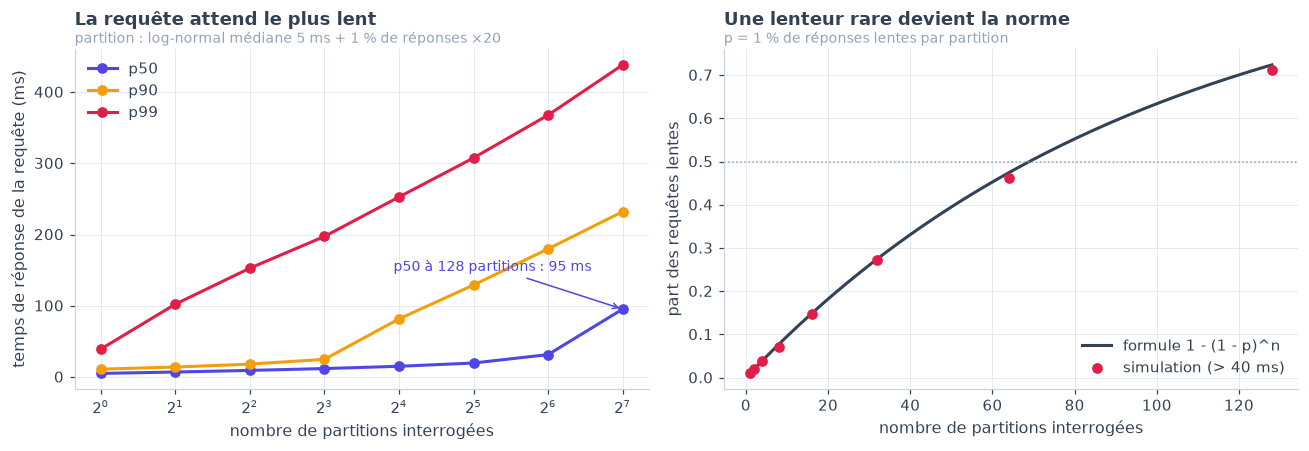

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
ax = axes[0]
for col, c in [("p50", INDIGO), ("p90", AMBER), ("p99", ROSE)]:
    ax.plot(sg.index, sg[col], marker="o", color=c, label=col)
ax.set_xscale("log", base=2)
ax.set_xlabel(f"nombre de {SHS} interrogé{FEM}s")
ax.set_ylabel("temps de réponse de la requête (ms)")
ax.set_title("La requête attend le plus lent")
subtitle(ax, f"{SH} : log-normal médiane 5 ms + 1 % de réponses ×20")
ax.annotate(f"p50 à {sg.index[-1]} {SHS} : {sg.p50.iloc[-1]:.0f} ms".replace(".", ","),
            (sg.index[-1], sg.p50.iloc[-1]), (-150, 25), textcoords="offset points",
            fontsize=9, color=INDIGO, arrowprops=dict(arrowstyle="->", color=INDIGO))
ax.legend()
ax = axes[1]
nn = np.arange(1, 129)
ax.plot(nn, 1 - 0.99 ** nn, color=SLATE, label="formule 1 - (1 - p)^n")
ax.scatter(sg.index, sg["P(lente) simulée"], color=ROSE, zorder=3, label="simulation (> 40 ms)")
ax.axhline(0.5, color=GRAY, ls=":", lw=1)
ax.set_xlabel(f"nombre de {SHS} interrogé{FEM}s")
ax.set_ylabel("part des requêtes lentes")
ax.set_title("Une lenteur rare devient la norme")
subtitle(ax, "p = 1 % de réponses lentes par " + SH)
ax.legend(loc="lower right")
plt.tight_layout(); plt.show()

La simulation suit la formule : avec 64 partitions, près d'une requête sur deux (46 %)
rencontre au moins une réponse lente. La médiane, elle, grimpe de 5 ms à 31 ms à 64
partitions puis 95 ms à 128, et le p99 passe de 39 ms à plus de 400 ms : au-delà
d'environ 70 partitions, la moitié des requêtes attendent un retardataire. (Le seuil de
40 ms sépare bien les deux régimes : une réponse normale ne le dépasse qu'environ trois
fois sur dix mille.)

**Le débit ne passe pas à l'échelle.** Second défaut, plus sournois : si chaque
requête par index secondaire sollicite toutes les partitions, chacune traite **toutes** ces
requêtes. Ajouter des partitions augmente la capacité de stockage et le débit des accès
par clé, mais pas celui des recherches. Si une fraction $f$ des requêtes est un
scatter/gather et le reste des lectures par clé, chaque requête coûte en moyenne
$(1 - f) + f\,n$ opérations de partition ; avec $n$ partitions de capacité $C$ chacune, le
débit maximal du cluster vaut

$$X(n) = \frac{n\,C}{(1 - f) + f\,n} \;\xrightarrow[n \to \infty]{}\; \frac{C}{f}.$$

C'est une loi d'Amdahl : la part de requêtes diffusées à tous plafonne le gain.

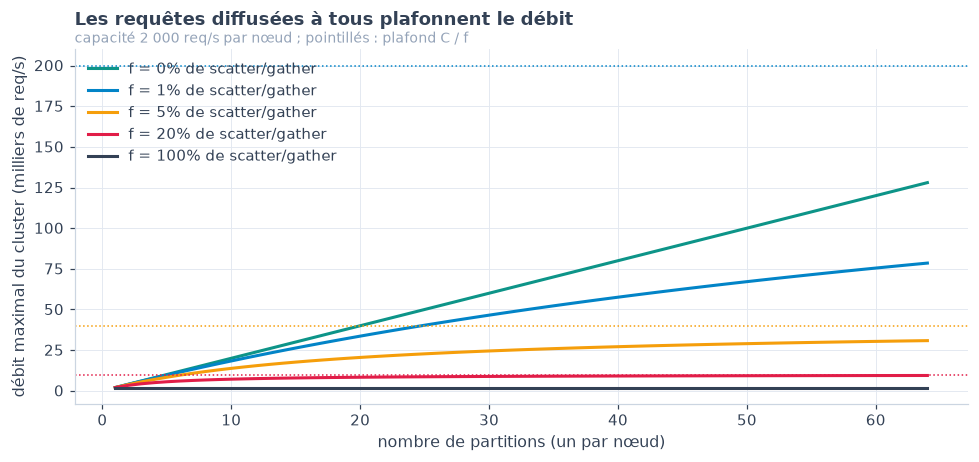

f =   1% : 16 nœuds ->  27 826 req/s ; 64 nœuds ->  78 528 req/s ; plafond 200 000
f =   5% : 16 nœuds ->  18 286 req/s ; 64 nœuds ->  30 843 req/s ; plafond 40 000
f =  20% : 16 nœuds ->   8 000 req/s ; 64 nœuds ->   9 412 req/s ; plafond 10 000


In [9]:
C = 2_000      # requêtes par seconde qu'un nœud sait traiter
n_axis = np.arange(1, 65)
fig, ax = plt.subplots(figsize=(9, 4.3))
for f, c in [(0.0, TEAL), (0.01, SKY), (0.05, AMBER), (0.2, ROSE), (1.0, SLATE)]:
    X = n_axis * C / ((1 - f) + f * n_axis)
    ax.plot(n_axis, X / 1e3, color=c, label=f"f = {f:.0%} de scatter/gather".replace(".", ","))
    if 0 < f < 1:
        ax.axhline(C / f / 1e3, color=c, ls=":", lw=1)
ax.set_xlabel(f"nombre de {SHS} (un par nœud)")
ax.set_ylabel("débit maximal du cluster (milliers de req/s)")
ax.set_title("Les requêtes diffusées à tous plafonnent le débit")
subtitle(ax, f"capacité {fmt(C)} req/s par nœud ; pointillés : plafond C / f")
ax.legend(loc="upper left")
plt.tight_layout(); plt.show()
for f in (0.01, 0.05, 0.2):
    print(f"f = {f:>4.0%} : 16 nœuds -> {16 * C / ((1 - f) + f * 16):>7,.0f} req/s ; 64 nœuds -> {64 * C / ((1 - f) + f * 64):>7,.0f} req/s ; plafond {C / f:,.0f}".replace(",", " "))

Avec 5 % de recherches par couleur, quadrupler le cluster de 16 à 64 nœuds ne fait
passer le débit que de 18 300 à 30 800 requêtes par seconde (plafond : 40 000). Avec
20 % de recherches, 64 nœuds ne traitent que 9 400 requêtes par seconde, à peine plus
que 16 nœuds (8 000) et moins que 5 nœuds sans aucune recherche (10 000). Les remèdes classiques : interroger des **répliques** différentes pour
répartir les lectures (chapitre 5), limiter le nombre de partitions sollicitées
quand on n'a besoin que de quelques résultats, ou envoyer des **requêtes de
couverture** pour couper la queue de latence.

> **À retenir.** Le scatter/gather est simple mais coûteux : la latence est celle
> de la plus lente des partitions (amplification de la queue), et chaque partition reçoit toutes les
> recherches, si bien que le débit des requêtes par index secondaire ne croît pas avec
> la taille du cluster.